# CS5 - Saturation-Model Selection & Sensitivity (well 30/6-5)

**Petrophys Case Studies - a decision-focused project notebook**

## Part 1 - The brief

> **"Which water-saturation model should we trust in this shaly sand, and how much
> does the choice move net pay and hydrocarbon pore volume (HCPV)? Quantify the
> sensitivity of the answer to both the *model* and the *parameter* assumptions."**

A subsurface team has a shaly-sand reservoir on the North Sea well **30/6-5**. The
gross rock volume is fixed by seismic; the volumetric uncertainty that the team
controls comes almost entirely from the **petrophysical water saturation (Sw)**. In a
*clean* sand Archie's equation is sufficient, but this interval carries dispersed clay,
and clay adds an extra conductive path that Archie does **not** account for - so Archie
reads Sw too high and undercounts pay. Several shaly-sand corrections exist
(Simandoux, Indonesia, Waxman-Smits, Dual-Water) and they disagree.

The deliverable of this notebook is **not** a single number. It is:

1. A **decision table** - the five Sw models side by side, each with mean Sw, net pay,
   and a hydrocarbon-pore-thickness (HCPT) index.
2. A **sensitivity / tornado analysis** - how much net pay and HCPT move when we sweep
   the key uncertain inputs (Rw, m, n, Vcl cutoff).
3. A **reasoned recommendation** - which model to trust here and why, with an
   **uncertainty band** on HCPV implied by the sensitivity.

This case study reuses the fundamentals taught in tutorial 07 (saturation) but is
oriented toward a *decision under uncertainty*, not toward teaching the equations.


## Part 2 - The well & the data

**Well 30/6-5** is a Geolink North Sea clastic well (depths in metres). It penetrates
two sand packages relevant to us:

| Interval | Depth (m) | Fluid | Role in this study |
|---|---|---|---|
| Brent / Baat sands | ~2841 - 2958 | hydrocarbon-bearing | **the reservoir** we evaluate |
| Statfjord sands | ~3223 - 3556 | water leg | **Pickett calibration** (Sw~1) |

The two-interval design is deliberate: a Pickett plot can only pin down the Archie
parameters (m, and via the intercept Rw) from a **water-bearing** zone where Sw is known
to be ~1. We use the deeper Statfjord water leg for that, then carry the parameters up
into the hydrocarbon interval.

**What we have:** GR, RHOB, NPHI, deep resistivity (RDEP), plus core (PHIC, SWC).
**What we are missing:** no measured Rw, no CEC/Qv lab data, no independent m/n from SCAL.
Every one of those becomes an *assumption* that we will flag and then stress-test in the
sensitivity analysis - which is exactly the point of the brief.


In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys
from petrophys.io import read_las
from petrophys.clay_volume import vcl_from_gr
from petrophys.petrophysics.porosity import (
    density_porosity, total_porosity, effective_porosity,
)
from petrophys.petrophysics.saturation import (
    archie, simandoux, indonesia, waxman_smits, dual_water,
)
from petrophys.petrophysics.cementation import pickett_analysis

print("petrophys", petrophys.__version__)

well = read_las(petrophys.sample("30_6-5"))
field = well.header.field
field_ascii = field.encode("ascii", "replace").decode("ascii") if field else "n/a"
print("well :", well.name)
print("field:", field_ascii)
print("depth: {:.1f} - {:.1f} {} ({} samples, step {:.3f} {})".format(
    well.start_depth, well.stop_depth, well.depth_unit,
    well.n_samples, well.step, well.depth_unit))
print("curves present:", ", ".join(c for c in ["GR","RHOB","NPHI","RDEP","PHIC","SWC"]
                                    if well.has_curve(c)))


petrophys 0.1.0


well : 30/6-5
field: OSEBERG ??ST
depth: 176.6 - 3556.1 m (22176 samples, step 0.152 m)
curves present: GR, RHOB, NPHI, RDEP, PHIC, SWC


## Part 3 - Workflow plan

The interpretation chain, and *why* in this order:

1. **Slice the two intervals** - reservoir (Brent/Baat) and water leg (Statfjord).
2. **Vcl from GR** (Larionov, older rocks) - the shale volume is the single input that
   the shaly-sand models need and that Archie ignores.
3. **Porosity** - density porosity -> total porosity (N/D) -> **effective** porosity via
   Vcl. Effective PHIE feeds Archie/Simandoux/Indonesia; total PHIT feeds
   Waxman-Smits/Dual-Water (they carry the clay-bound water themselves).
4. **Pickett plot on the water leg** - derive an illustrative *m* and *Rw*. We will see
   the log-only Pickett is poorly constrained here and make a *judgement call* on the
   base-case m/n - a realistic petrophysical decision.
5. **Run all five Sw models** over the reservoir with one common parameter set.
6. **Decision table** - mean Sw, net pay, HCPT per model under a fixed cutoff set.
7. **Parameter sensitivity** - sweep Rw, m, n and the Vcl cutoff; build a tornado.
8. **Recommendation** - pick a model, quote an HCPV uncertainty band.

We keep the calls granular (rather than a single `run_dynamic_workflow`) *precisely
because* the deliverable is a controlled sensitivity sweep: we need to vary one
assumption at a time and re-evaluate, which is cleanest with explicit function calls.


## Part 4 - Execution

### 4.1 Slice the intervals and compute Vcl + porosity

We build a small helper that, given a depth-sliced well, returns Vcl, PHIT and PHIE on a
consistent basis so the reservoir and the water leg are processed identically.

In [2]:
RES_TOP, RES_BOT = 2841.0, 2958.0      # Brent/Baat hydrocarbon sands
WAT_TOP, WAT_BOT = 3223.0, 3556.0      # Statfjord water leg (Sw ~ 1)

RHO_MA, RHO_FL = 2.65, 1.0             # sandstone matrix, fresh mud filtrate
PHI_CLAY = 0.15                        # clay porosity for PHIE (assumed)

def evaluate_interval(w, top, bot, gr_method="larionov_older"):
    seg = w.depth_slice(top, bot)
    gr   = seg.get("GR").data
    rhob = seg.get("RHOB").data
    nphi = seg.get("NPHI").data
    rt   = seg.get("RDEP").data
    depth = seg.depth
    dz = seg.step
    # GR endpoints from robust percentiles of THIS interval
    gr_min = float(np.nanpercentile(gr, 5))
    gr_max = float(np.nanpercentile(gr, 95))
    vcl  = np.clip(vcl_from_gr(gr, gr_min, gr_max, method=gr_method), 0.0, 1.0)
    phid = density_porosity(rhob, RHO_MA, RHO_FL)
    phit = np.clip(total_porosity(nphi, phid, method="adaptive"), 0.001, 0.45)
    phie = np.clip(effective_porosity(phit, vcl, phi_clay=PHI_CLAY), 0.001, 0.40)
    return dict(depth=depth, dz=dz, gr=gr, rt=rt,
                vcl=vcl, phit=phit, phie=phie,
                gr_min=gr_min, gr_max=gr_max)

res = evaluate_interval(well, RES_TOP, RES_BOT)
wat = evaluate_interval(well, WAT_TOP, WAT_BOT)

print("RESERVOIR  {:.0f}-{:.0f} m  ({} samples, dz={:.4f} m)".format(
    RES_TOP, RES_BOT, len(res["depth"]), res["dz"]))
print("  GR endpoints (5/95 pct): {:.1f} / {:.1f} API".format(res["gr_min"], res["gr_max"]))
print("  mean Vcl={:.3f}  PHIT={:.3f}  PHIE={:.3f}".format(
    np.nanmean(res["vcl"]), np.nanmean(res["phit"]), np.nanmean(res["phie"])))
print("WATER LEG  {:.0f}-{:.0f} m  ({} samples)".format(
    WAT_TOP, WAT_BOT, len(wat["depth"])))
print("  mean Vcl={:.3f}  PHIT={:.3f}  PHIE={:.3f}".format(
    np.nanmean(wat["vcl"]), np.nanmean(wat["phit"]), np.nanmean(wat["phie"])))
print()
print("NOTE: mean Vcl ~ 0.36 confirms this is a SHALY sand - Archie will be biased high.")


RESERVOIR  2841-2958 m  (768 samples, dz=0.1523 m)
  GR endpoints (5/95 pct): 26.2 / 106.5 API
  mean Vcl=0.356  PHIT=0.193  PHIE=0.139
WATER LEG  3223-3556 m  (2185 samples)
  mean Vcl=0.409  PHIT=0.110  PHIE=0.054

NOTE: mean Vcl ~ 0.36 confirms this is a SHALY sand - Archie will be biased high.


### 4.2 Pickett plot on the water leg -> illustrative m and Rw

The Pickett plot is `log(Rt)` vs `log(PHI)` for water-bearing points; the slope gives
`-m` and the intercept gives `log(a*Rw)`. We restrict to the cleaner, higher-porosity
Statfjord points (Vcl < 0.30) and call `pickett_analysis`.

**Important caveat, up front:** `pickett_analysis` regresses on log-log data and returns
`n = 2.0` by construction (it fits *m* and *a* only; *n* comes from SCAL, which we do not
have). On this real well the water-leg cloud is heterogeneous (variable Rw, mixed
lithology), so the log-only *m* comes out unphysically low with a weak R-squared. We will
therefore treat the fitted *m* as **illustrative** and make an explicit judgement call for
the base case.

In [3]:
ap, pk = pickett_analysis(wat["rt"], wat["phie"], vcl=wat["vcl"], vcl_cutoff=0.30)

Rw_pickett = 10.0 ** pk["intercept"]     # intercept = log10(a*Rw), a=1
print("Pickett fit on Statfjord water leg (Vcl<0.30):")
print("  n_points  = {}".format(pk["n_points"]))
print("  m (slope) = {:.3f}".format(pk["m"]))
print("  R-squared = {:.3f}".format(pk["r_squared"]))
print("  intercept = {:.3f}  -> Rw (a=1) = {:.4f} ohm.m".format(
    pk["intercept"], Rw_pickett))
print()
print("READ-OUT: the log-only m={:.2f} is well below the physical 1.6-2.1 range and the".format(pk["m"]))
print("R-squared is poor -> the water-leg cloud does NOT constrain m reliably on this well.")


Pickett fit on Statfjord water leg (Vcl<0.30):
  n_points  = 880
  m (slope) = 0.628
  R-squared = 0.600
  intercept = -0.017  -> Rw (a=1) = 0.9614 ohm.m

READ-OUT: the log-only m=0.63 is well below the physical 1.6-2.1 range and the
R-squared is poor -> the water-leg cloud does NOT constrain m reliably on this well.


**Judgement call (flagged).** Because the log-derived Pickett *m* is unreliable
here, we adopt a **North-Sea-typical clean-sand base case** for the deterministic run and
then *stress-test it* in the sensitivity section - which is the honest way to handle a
weak calibration:

- `m = 1.8`, `n = 2.0`, `a = 1.0` (typical for a moderately consolidated shaly sand)
- `Rw = 0.05` ohm.m (saline North Sea formation water; the Pickett intercept is only
  used as a sanity anchor, not adopted verbatim because it inherits the bad slope)

These are **assumptions**. Their impact is exactly what the tornado in Part 7 quantifies.

In [4]:
# ---- Base-case parameter set (all flagged as assumptions) ----
BASE = dict(
    Rw   = 0.05,     # ohm.m, assumed saline formation water
    a    = 1.0,      # tortuosity
    m    = 1.8,      # cementation exponent (judgement, Pickett unreliable)
    n    = 2.0,      # saturation exponent (no SCAL -> textbook value)
    Rcl  = 3.0,      # clay/shale resistivity (ohm.m), from shaly response
)
# Clay parameters for the CEC / bound-water models (assumed, no lab data)
CEC     = 0.05       # meq/g  (dispersed illite/smectite, order-of-magnitude)
B_COEFF = 4.0        # clay counter-ion conductance (~formation temp)
PHI_CL  = 0.35       # clay porosity for Dual-Water bound-water term

# ---- Cutoff set for net pay / HCPT (fixed for the decision table) ----
CUT = dict(vcl=0.35, phie=0.08, sw=0.50)

print("Base parameters:", BASE)
print("Cutoffs        :", CUT)


Base parameters: {'Rw': 0.05, 'a': 1.0, 'm': 1.8, 'n': 2.0, 'Rcl': 3.0}
Cutoffs        : {'vcl': 0.35, 'phie': 0.08, 'sw': 0.5}


### 4.3 Run all five saturation models

Model families and what each one is *for*:

| Model | Porosity basis | Clay term | When you reach for it |
|---|---|---|---|
| **Archie** | PHIE | none | clean sand baseline (biased high in shaly rock) |
| **Simandoux** | PHIE | `Vcl/Rcl` (linear) | classic shaly-sand, dispersed clay |
| **Indonesia** (Poupon-Leveaux) | PHIE | `Vcl^(2-Vcl)/Rcl` | laminated/dispersed, high-Vcl robust |
| **Waxman-Smits** | PHIT | CEC / Qv | when you have CEC lab data (here assumed) |
| **Dual-Water** | PHIT | bound-water (Rwb) | clay-bound water separated explicitly |

Note the two porosity bases: the effective-porosity models take **PHIE**, while the
total-porosity models (Waxman-Smits, Dual-Water) take **PHIT** and carry the clay water
themselves. Feeding the wrong porosity is a classic error, so we are explicit.

In [5]:
rt   = res["rt"]
vcl  = res["vcl"]
phie = res["phie"]
phit = res["phit"]

def run_models(Rw, m, n, Rcl, a=1.0):
    sw = {}
    sw["Archie"]       = np.clip(archie(rt, Rw, phie, a, m, n), 0, 1)
    sw["Simandoux"]    = np.clip(simandoux(rt, Rw, phie, vcl, Rcl, a, m, n), 0, 1)
    sw["Indonesia"]    = np.clip(indonesia(rt, Rw, phie, vcl, Rcl, a, m, n), 0, 1)
    sw["Waxman-Smits"] = np.clip(waxman_smits(phit, rt, Rw, cec=CEC, rho_ma=RHO_MA,
                                              b_coeff=B_COEFF, m_star=m, n=n), 0, 1)
    sw["Dual-Water"]   = np.clip(dual_water(phit, rt, Rw, rwb=0.3*Rw, vcl=vcl,
                                            phi_cl=PHI_CL, a=a, m=m, n=n), 0, 1)
    return sw

sw_base = run_models(BASE["Rw"], BASE["m"], BASE["n"], BASE["Rcl"], BASE["a"])

for name, sw in sw_base.items():
    print("  {:14s} mean Sw = {:.3f}".format(name, float(np.nanmean(sw))))


  Archie         mean Sw = 0.675
  Simandoux      mean Sw = 0.562
  Indonesia      mean Sw = 0.548
  Waxman-Smits   mean Sw = 0.460
  Dual-Water     mean Sw = 0.143


### 4.4 Net pay & HCPT from a fixed cutoff set

For each model we apply the same three-part reservoir/pay flags and integrate:

- **Reservoir**: `Vcl < 0.35` and `PHIE > 0.08`
- **Pay**: reservoir **and** `Sw < 0.50`
- **Net pay** = (pay samples) x sample thickness `dz`
- **HCPT** (hydrocarbon-pore-thickness) = sum over pay of `PHIE * (1 - Sw) * dz`

HCPT is a per-well HCPV *index* (m of hydrocarbon-filled pore column). Multiplied by area
it becomes HCPV; because area is common to all models, HCPT captures the full model
sensitivity of the volumetric answer.

In [6]:
DZ = res["dz"]

def net_pay_hcpt(sw, vcl_cut=CUT["vcl"], phie_cut=CUT["phie"], sw_cut=CUT["sw"]):
    reservoir = (vcl < vcl_cut) & (phie > phie_cut)
    pay = reservoir & (sw < sw_cut)
    net_pay = float(np.sum(pay) * DZ)
    hcpt = float(np.sum(phie[pay] * (1.0 - sw[pay]) * DZ))
    mean_sw_pay = float(np.nanmean(sw[pay])) if np.any(pay) else float("nan")
    return net_pay, hcpt, mean_sw_pay

rows = []
for name, sw in sw_base.items():
    npay, hcpt, msw_pay = net_pay_hcpt(sw)
    rows.append(dict(Model=name,
                     Mean_Sw=round(float(np.nanmean(sw)), 3),
                     Mean_Sw_pay=round(msw_pay, 3),
                     Net_pay_m=round(npay, 2),
                     HCPT_m=round(hcpt, 3)))

decision = pd.DataFrame(rows).set_index("Model")
print(decision.to_string())


              Mean_Sw  Mean_Sw_pay  Net_pay_m  HCPT_m
Model                                                
Archie          0.675        0.260      28.79   4.447
Simandoux       0.562        0.256      30.77   4.693
Indonesia       0.548        0.268      33.36   4.908
Waxman-Smits    0.460        0.242      36.26   5.378
Dual-Water      0.143        0.143      56.67   8.590


## Part 5 - Integrated result

### 5.1 Figure - the reservoir interval (Vcl, porosity, and the 5-model Sw overlay)

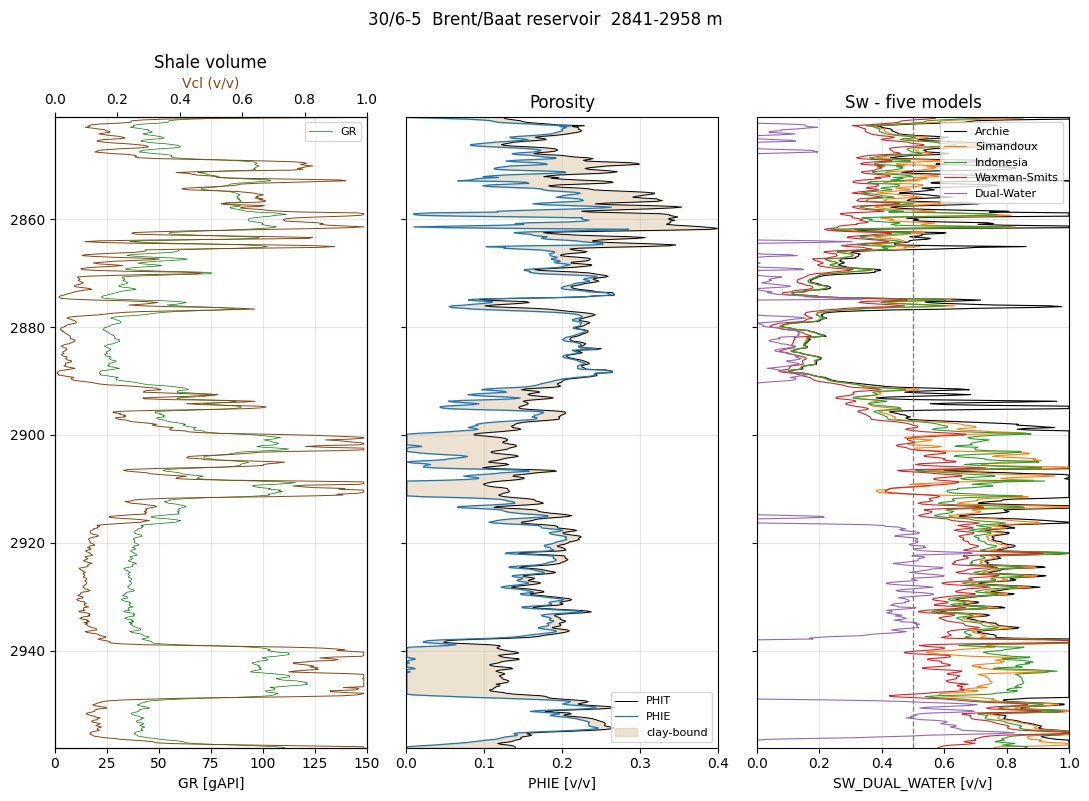

Track 3 shows the spread: Archie (black) sits right of the shaly-sand models,
i.e. Archie reads the wettest -> the least pay, as physics predicts.


In [7]:
from petrophys.visualization import LogPlot

# Build a reservoir-interval well and attach the computed curves so the library
# LogPlot can render the composite. (GR is already on the sliced well.)
res_well = well.depth_slice(RES_TOP, RES_BOT)
res_well.add_curve("VCL",  vcl,  unit="v/v")
res_well.add_curve("PHIT", phit, unit="v/v")
res_well.add_curve("PHIE", phie, unit="v/v")
model_colors = dict(Archie="black", Simandoux="tab:orange", Indonesia="tab:green",
                    **{"Waxman-Smits": "tab:red", "Dual-Water": "tab:purple"})
for name, sw in sw_base.items():
    res_well.add_curve("SW_" + name.replace("-", "_").upper(), sw, unit="v/v")

lp = LogPlot(res_well, figsize=(11, 8))
lp.create_figure(n_tracks=3)

# Track 1: GR + Vcl (Vcl on a twin axis)
lp.add_curve(0, "GR", color="green", xlim=(0, 150))
lp.axes[0].set_title("Shale volume")
ax0b = lp.axes[0].twiny()
ax0b.plot(vcl, res_well.depth, color="saddlebrown", lw=0.7)
ax0b.set_xlabel("Vcl (v/v)", color="saddlebrown"); ax0b.set_xlim(0, 1)

# Track 2: porosity (PHIT, PHIE, clay-bound fill)
lp.add_curve(1, "PHIT", color="black", linewidth=0.7, xlim=(0, 0.4), label="PHIT")
lp.add_curve(1, "PHIE", color="tab:blue", linewidth=0.9, xlim=(0, 0.4), label="PHIE")
lp.axes[1].fill_betweenx(res_well.depth, phie, phit, color="tan", alpha=0.4, label="clay-bound")
lp.axes[1].legend(loc="lower right", fontsize=8); lp.axes[1].set_title("Porosity")

# Track 3: Sw overlay of the 5 models
for name in sw_base:
    lp.add_curve(2, "SW_" + name.replace("-", "_").upper(), color=model_colors[name],
                 linewidth=0.8, xlim=(0, 1), label=name)
lp.axes[2].axvline(CUT["sw"], color="gray", ls="--", lw=1)
lp.axes[2].set_title("Sw - five models")

lp.set_depth_range()
lp.fig.suptitle("30/6-5  Brent/Baat reservoir  {:.0f}-{:.0f} m".format(RES_TOP, RES_BOT), y=0.995)
lp.show()
print("Track 3 shows the spread: Archie (black) sits right of the shaly-sand models,")
print("i.e. Archie reads the wettest -> the least pay, as physics predicts.")

### 5.2 Figure - net pay and HCPT by model (the decision bar chart)

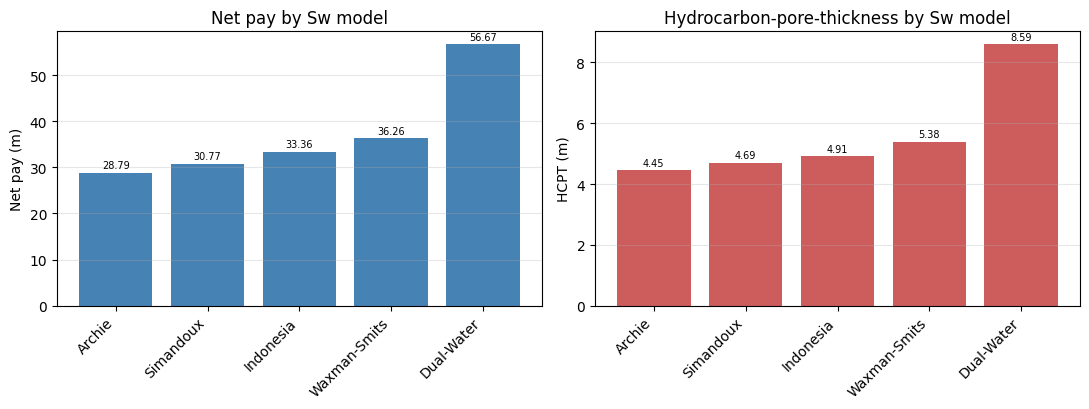

MODEL spread: net pay ranges 27.9 m, HCPT ranges 4.14 m
-> the choice of model alone moves HCPV by ~84%.


In [8]:
from petrophys.visualization import create_bar_comparison

names = list(decision.index)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))

create_bar_comparison(names, decision["Net_pay_m"].values, colors=["steelblue"] * len(names),
                      value_labels=True, ylabel="Net pay (m)",
                      title="Net pay by Sw model", ax=ax[0])
create_bar_comparison(names, decision["HCPT_m"].values, colors=["indianred"] * len(names),
                      value_labels=True, ylabel="HCPT (m)",
                      title="Hydrocarbon-pore-thickness by Sw model", ax=ax[1])

plt.tight_layout()
plt.show()

spread_np = decision["Net_pay_m"].max() - decision["Net_pay_m"].min()
spread_hc = decision["HCPT_m"].max() - decision["HCPT_m"].min()
print("MODEL spread: net pay ranges {:.1f} m, HCPT ranges {:.2f} m".format(spread_np, spread_hc))
print("-> the choice of model alone moves HCPV by ~{:.0f}%.".format(
    100*spread_hc/decision["HCPT_m"].median()))

### 5.3 Figure - model-vs-model Sw crossplot (Archie vs Indonesia)

If two models were interchangeable, points would lie on the 1:1 line. The systematic
departure below the line quantifies how much clay conductivity Archie mis-attributes to
water.

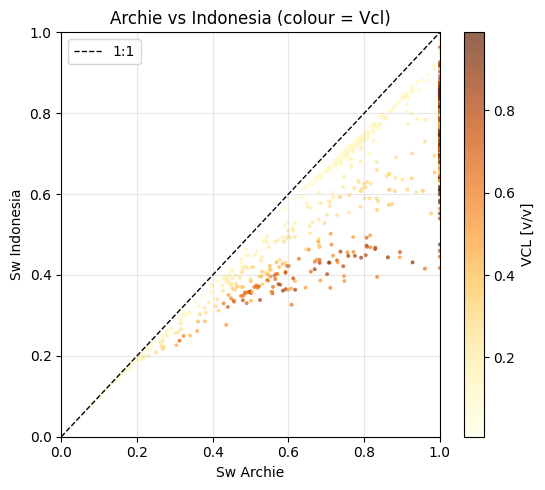

Mean Sw(Archie) - Sw(Indonesia) = +0.127
Points sit BELOW 1:1 and the gap widens with Vcl -> Archie's high-Sw bias is
clay-driven, exactly the effect the shaly-sand models remove.


In [9]:
from petrophys.visualization import create_crossplot

# Archie vs Indonesia Sw crossplot, coloured by Vcl, rendered by the library
# crossplot. res_well already carries SW_ARCHIE, SW_INDONESIA and VCL.
cp = create_crossplot(
    res_well, "SW_ARCHIE", "SW_INDONESIA", color_curve="VCL",
    xlim=(0, 1), ylim=(0, 1), cmap="YlOrBr", marker_size=8, figsize=(5.6, 5),
    title="Archie vs Indonesia (colour = Vcl)",
)
cp.add_line([0, 1], [0, 1], color="black", linestyle="--", label="1:1")
cp.ax.set_xlabel("Sw Archie"); cp.ax.set_ylabel("Sw Indonesia")
cp.show()

sw_ar = sw_base["Archie"]; sw_in = sw_base["Indonesia"]
good = ~np.isnan(sw_ar) & ~np.isnan(sw_in)
dsw = float(np.nanmean(sw_ar[good] - sw_in[good]))
print("Mean Sw(Archie) - Sw(Indonesia) = {:+.3f}".format(dsw))
print("Points sit BELOW 1:1 and the gap widens with Vcl -> Archie's high-Sw bias is")
print("clay-driven, exactly the effect the shaly-sand models remove.")

## Part 6 - Parameter sensitivity (the tornado)

The decision table captured **model** uncertainty. Now we quantify **parameter**
uncertainty for a single reference model. We use **Indonesia** as the reference (it is the
robust workhorse for dispersed shaly sands and sits mid-pack in the table), and sweep each
key input across a defensible low/high range while holding the others at base:

| Assumption | Low | Base | High | Why uncertain |
|---|---|---|---|---|
| Rw (ohm.m) | 0.03 | 0.05 | 0.08 | no measured Rw |
| m | 1.6 | 1.8 | 2.0 | Pickett unreliable |
| n | 1.8 | 2.0 | 2.2 | no SCAL |
| Vcl cutoff | 0.30 | 0.35 | 0.40 | pay-flag choice |

For each we record HCPT (and net pay) at low and high, and draw a **tornado**: the widest
bar is the assumption the answer is most sensitive to - i.e. where a measurement would buy
the most certainty.

In [10]:
def indo_case(Rw=BASE["Rw"], m=BASE["m"], n=BASE["n"],
              Rcl=BASE["Rcl"], vcl_cut=CUT["vcl"]):
    sw = np.clip(indonesia(rt, Rw, phie, vcl, Rcl, BASE["a"], m, n), 0, 1)
    npay, hcpt, _ = net_pay_hcpt(sw, vcl_cut=vcl_cut)
    return npay, hcpt

base_np, base_hc = indo_case()
print("Indonesia BASE: net pay = {:.2f} m, HCPT = {:.3f} m".format(base_np, base_hc))

sweeps = {
    "Rw":       dict(low=dict(Rw=0.03),      high=dict(Rw=0.08)),
    "m":        dict(low=dict(m=1.6),        high=dict(m=2.0)),
    "n":        dict(low=dict(n=1.8),        high=dict(n=2.2)),
    "Vcl cutoff": dict(low=dict(vcl_cut=0.30), high=dict(vcl_cut=0.40)),
}

sens_rows = []
for label, ends in sweeps.items():
    np_lo, hc_lo = indo_case(**ends["low"])
    np_hi, hc_hi = indo_case(**ends["high"])
    sens_rows.append(dict(Assumption=label,
                          HCPT_low=round(hc_lo, 3), HCPT_high=round(hc_hi, 3),
                          NetPay_low=round(np_lo, 2), NetPay_high=round(np_hi, 2),
                          HCPT_span=round(abs(hc_hi - hc_lo), 3)))

sens = pd.DataFrame(sens_rows).sort_values("HCPT_span", ascending=True).reset_index(drop=True)
print()
print(sens.to_string(index=False))


Indonesia BASE: net pay = 33.36 m, HCPT = 4.908 m

Assumption  HCPT_low  HCPT_high  NetPay_low  NetPay_high  HCPT_span
Vcl cutoff     4.715      4.979       31.38        34.13      0.264
         n     5.227      4.525       34.89        30.77      0.701
         m     5.446      4.340       37.78        28.95      1.107
        Rw     5.780      4.117       40.22        27.58      1.663


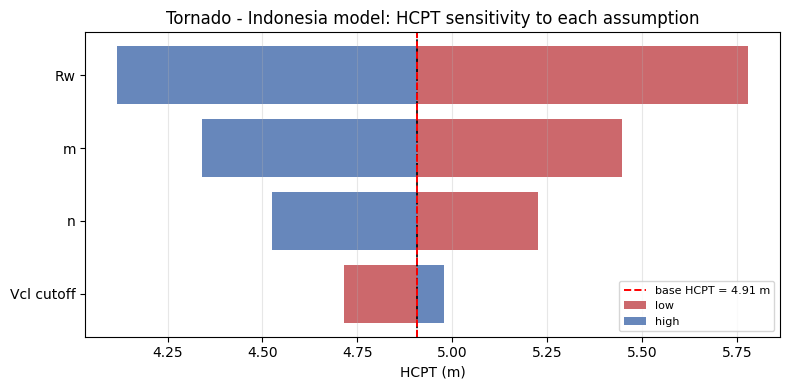

Most sensitive assumption: Rw (HCPT span 1.66 m).
A measured Rw would remove the largest single chunk of volumetric uncertainty.


In [11]:
from petrophys.visualization import create_tornado_plot

# Tornado: HCPT low/high outcome for each swept assumption about the base case,
# rendered by the library tornado plotter (it sorts widest-span to the top).
fig, ax = create_tornado_plot(
    sens["Assumption"].tolist(),
    sens["HCPT_low"].values,
    sens["HCPT_high"].values,
    base=base_hc,
    xlabel="HCPT (m)",
    figsize=(8, 4),
    title="Tornado - Indonesia model: HCPT sensitivity to each assumption",
)
ax.axvline(base_hc, color="red", ls="--", lw=1.4, label="base HCPT = {:.2f} m".format(base_hc))
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

top = sens.iloc[-1]
print("Most sensitive assumption: {} (HCPT span {:.2f} m).".format(
    top["Assumption"], top["HCPT_span"]))
print("A measured Rw would remove the largest single chunk of volumetric uncertainty.")

### 6.1 Combining model + parameter uncertainty into an HCPV band

To quote an honest range we combine both sources:

- **Low case**: the most pessimistic *model* (Archie) at its most pessimistic parameter
  corner.
- **High case**: an optimistic shaly-sand model at its most optimistic parameter corner.
- **Base case**: our recommended model at base parameters.

We express the band as HCPT and as a percentage around the recommended base.

In [12]:
# Recommended model = Indonesia (justified in Part 7). Build a combined band.
def model_case(model_fn_name, Rw, m, n, Rcl, vcl_cut):
    smap = run_models(Rw, m, n, Rcl, BASE["a"])
    npay, hcpt, _ = net_pay_hcpt(smap[model_fn_name], vcl_cut=vcl_cut)
    return npay, hcpt

# base (recommended)
rec_np, rec_hc, _ = net_pay_hcpt(sw_base["Indonesia"])

# low case: Archie + high Rw + high m + high n + tight cutoff
low_np, low_hc = model_case("Archie", Rw=0.08, m=2.0, n=2.2, Rcl=BASE["Rcl"], vcl_cut=0.30)
# high case: Indonesia + low Rw + low m + low n + loose cutoff
high_np, high_hc = model_case("Indonesia", Rw=0.03, m=1.6, n=1.8, Rcl=BASE["Rcl"], vcl_cut=0.40)

band = pd.DataFrame([
    dict(Case="Low  (Archie, pessimistic params)",    Net_pay_m=round(low_np,2),  HCPT_m=round(low_hc,3)),
    dict(Case="Base (Indonesia, base params)",        Net_pay_m=round(rec_np,2),  HCPT_m=round(rec_hc,3)),
    dict(Case="High (Indonesia, optimistic params)",  Net_pay_m=round(high_np,2), HCPT_m=round(high_hc,3)),
]).set_index("Case")
print(band.to_string())
print()
lo_pct = 100*(low_hc-rec_hc)/rec_hc
hi_pct = 100*(high_hc-rec_hc)/rec_hc
print("HCPV band vs base: {:+.0f}% / {:+.0f}%  (HCPT {:.2f} - {:.2f} m, base {:.2f} m)".format(
    lo_pct, hi_pct, low_hc, high_hc, rec_hc))


                                     Net_pay_m  HCPT_m
Case                                                  
Low  (Archie, pessimistic params)        19.35   2.951
Base (Indonesia, base params)            33.36   4.908
High (Indonesia, optimistic params)      67.34   8.738

HCPV band vs base: -40% / +78%  (HCPT 2.95 - 8.74 m, base 4.91 m)


## Part 7 - Recommendation & deliverable

**Recommended model: Indonesia (Poupon-Leveaux).**

Reasoning:

1. **The rock is shaly.** Mean Vcl ~ 0.36 with dispersed clay. Archie ignores clay
   conductivity and reads the wettest of the five models - it *systematically undercounts
   pay* here (see the Archie-vs-Indonesia crossplot, where the gap grows with Vcl). Archie
   is the wrong tool for this interval and is kept only as a pessimistic bookend.

2. **Indonesia is the right shaly-sand workhorse.** Its `Vcl^(2-Vcl)` clay term is
   numerically stable across the full 0-0.6 Vcl range seen here and does not require lab
   data we do not have. Simandoux tracks it closely but is less robust at high Vcl.

3. **Waxman-Smits and Dual-Water are data-starved.** Both need clay-specific inputs
   (CEC/Qv, Rwb, clay porosity) that we had to *assume*. Dual-Water in particular is very
   sensitive to the assumed clay porosity and here returns an optimistically low Sw. Their
   answers are only as good as guessed inputs, so we do not trust them as the base case -
   they inform the *upper* edge of the uncertainty band instead.

4. **Indonesia sits mid-pack**, giving a balanced, defensible central estimate rather than
   the extreme of either bookend.

**Deliverable - the numbers with their uncertainty:**

- **Recommended (Indonesia, base):** net pay and HCPT as printed in the band table above.
- **HCPV uncertainty band** (model + parameter, combined): the low/high percentages
  printed above. The band is dominated by **Rw**, then **m** - so the single highest-value
  next measurement is a **produced-water Rw** (or a good Pickett from a cleaner offset).

The honest headline for the team: *the shaly-sand correction moves HCPV materially versus
Archie, and the residual volumetric uncertainty is set mainly by Rw. Book the Indonesia
base case, carry the band, and prioritise an Rw measurement before committing volumes.*


## Part 8a - Limitations & assumptions

Everything below was **assumed**, not measured, and each is a candidate for the next
data-acquisition dollar:

- **Rw = 0.05 ohm.m** - no measured formation-water resistivity. The tornado shows this is
  the dominant volumetric lever.
- **m = 1.8, n = 2.0** - the log-only Pickett on the Statfjord water leg was poorly
  constrained (unphysical slope, weak R-squared), so m/n are judgement values, not SCAL.
  The Pickett result is reported as **illustrative** only.
- **CEC, B, clay porosity, Rwb** - no core electrical or CEC data; the Waxman-Smits and
  Dual-Water inputs are order-of-magnitude guesses, which is why those models bound rather
  than set the answer.
- **GR endpoints** from interval percentiles, not a hand-picked clean/shale baseline.
- **Fixed cutoff set** (Vcl 0.35 / PHIE 0.08 / Sw 0.50) - reasonable but project-specific;
  the Vcl cutoff was included in the sensitivity to show its (modest) effect.
- **HCPT is a per-well column index**, not a mapped HCPV - area/NTG closure comes from the
  static model, which is outside this notebook's scope.


## Part 8b - Appendix: reproduce on another well

To repeat this study on a different well, change the sample and the two intervals; the
helper functions do the rest.

```python
w2 = read_las(petrophys.sample("<well_id>"))       # e.g. another Geolink well
res2 = evaluate_interval(w2, <res_top>, <res_bot>) # hydrocarbon interval
wat2 = evaluate_interval(w2, <wat_top>, <wat_bot>) # water leg for Pickett
# then re-run: pickett_analysis -> run_models -> net_pay_hcpt -> decision table -> tornado
```

Guidance for a new well:
- Pick the **water leg** for Pickett from a zone you independently believe is Sw~1; if the
  fit is weak (low R-squared, m outside 1.6-2.1), treat it as illustrative and fall back to
  a basin-typical m/n as we did here.
- Keep the **five-model** run and the **tornado** - the decision value is in the *spread*
  and in identifying the *most sensitive assumption*, not in any single deterministic Sw.
